# Customer Churn Analysis

**Dataset:** Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)

**Objective:** Explore the Telco customer data to understand which factors are associated with customers leaving (churn).

## Table of Contents

1. Import Libraries
2. Load and Understand the Dataset
3. Data Inspection and Cleaning
4. Exploratory Data Analysis (EDA)
   - 4.1 Target Variable: Churn Distribution
   - 4.2 Numerical Analysis
   - 4.3 Categorical Analysis
   - 4.4 Relationship Analysis

## 1. Import Libraries

Import the libraries used for data handling and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load and Understand the Dataset

Load the CSV file and get a first look at its structure.

### 2.1 Load the Data

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

### 2.2 Dataset Preview

In [3]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


### 2.3 Dataset Info

Column data types and non-null counts.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 2.4 First 10 Records

In [5]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


### 2.5 Dataset Shape

Number of rows and columns.

In [6]:
df.shape

(7043, 21)

### 2.6 Column Names

In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## 3. Data Inspection and Cleaning

Check for missing values, duplicates and incorrect data types.

### 3.1 Missing Values

Count and percentage of missing values in each column.

In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
missing_count =  df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_summary = pd.DataFrame({
    "Missing_Count" : missing_count,
    "Missing_Percentage" : missing_percentage
})

missing_summary.sort_values(by="Missing_Percentage",ascending=False)

,Missing_Count,Missing_Percentage
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [10]:
#missing_count
missing_percentage

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

### 3.2 Duplicate Records

Check for duplicate rows and duplicate customer IDs.

In [11]:
duplicates = df.duplicated().sum()

In [12]:
duplicates

np.int64(0)

In [13]:
df["customerID"].duplicated(keep=False).sum()

np.int64(0)

### 3.3 Fixing the `TotalCharges` Data Type

`TotalCharges` is stored as text. Inspect its values, find blank entries, and convert the column to numeric.

In [14]:
print(df["TotalCharges"].dtype)

str


In [15]:
df["TotalCharges"].value_counts()

TotalCharges
20.2      11
          11
19.75      9
19.9       8
20.05      8
          ..
1990.5     1
7362.9     1
346.45     1
306.6      1
6844.5     1
Name: count, Length: 6531, dtype: int64

In [16]:
blank_mask = (
    df["TotalCharges"]
    .astype("string")
    .str.strip()
    .eq("")
)

df.loc[blank_mask, ["customerID", "tenure", "TotalCharges"]]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [17]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [19]:
df["TotalCharges"].dtype

dtype('float64')

In [20]:
df["TotalCharges"].isnull().sum()

np.int64(11)

### 3.4 Cleaning Summary

Overview of shape, duplicates, missing values and data types after cleaning.

In [21]:
print("Dataset shape:", df.shape)
print(
    "Duplicate rows:",
    df.duplicated().sum()
)
print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)
print("\nMissing values by column:")
print(
    df.isnull().sum()
    .sort_values(ascending=False)
    
)

print("\nData types:")
print(df.dtypes)

Dataset shape: (7043, 21)
Duplicate rows: 0
Duplicate customer IDs: 0

Missing values by column:
TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
Contract             0
StreamingMovies      0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
Churn                0
dtype: int64

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
St

## 4. Exploratory Data Analysis (EDA)

Analyze the target variable, numerical features, categorical features and their relationship with churn.

### 4.1 Target Variable: Churn Distribution

How many customers churned versus stayed.

In [22]:
# Count customers in each churn category

In [23]:
churn_count = df["Churn"].value_counts()

In [24]:
churn_percentage =  (df['Churn'].value_counts(normalize=True)*100)

In [25]:
print("Customer counts:")
print(churn_count)

print("\nCustomer percentages:")
print(churn_percentage.round(2))

Customer counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [26]:
# Visualize the churn distribution

Total : 7043
5174.0
1869.0


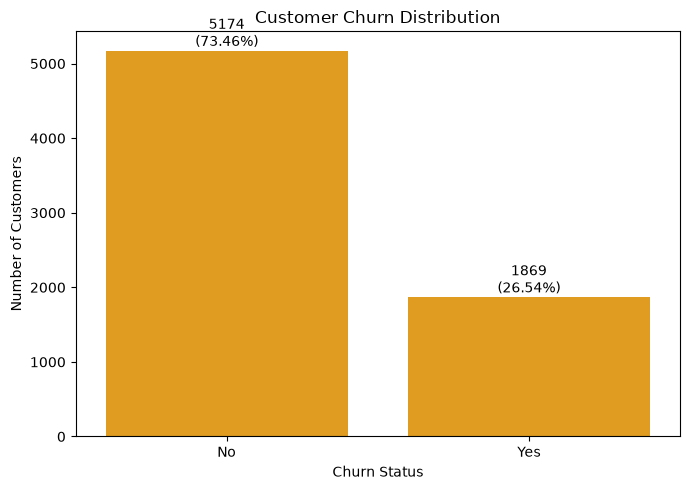

In [27]:
plt.figure(figsize=(7,5))
ax = sns.countplot(data= df , x = "Churn",color="orange")

#ax.bar_label(ax.containers[0])

total = len(df)
print(f"Total : {total}")

for bar in ax.patches:
    count = bar.get_height()
    print(count)
    percentage = (count / total ) * 100

    ax.annotate(
        f"{count:.0f}\n({percentage:.2f}%)",
        (bar.get_x() + bar.get_width() / 2 , count),
        ha= "center",
        va= "bottom"
    )

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.show()

### 4.2 Numerical Analysis

Analysis of `tenure`, `MonthlyCharges` and `TotalCharges`.

#### 4.2.1 Tenure

Descriptive statistics, distribution, and comparison between churned and retained customers.

In [28]:
#Descriptive statistics

In [29]:
df[["tenure","MonthlyCharges","TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [30]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [31]:
df["tenure"].value_counts().sort_index()

tenure
0      11
1     613
2     238
3     200
4     176
     ... 
68    100
69     95
70    119
71    170
72    362
Name: count, Length: 73, dtype: int64

In [32]:
# Create a histogram

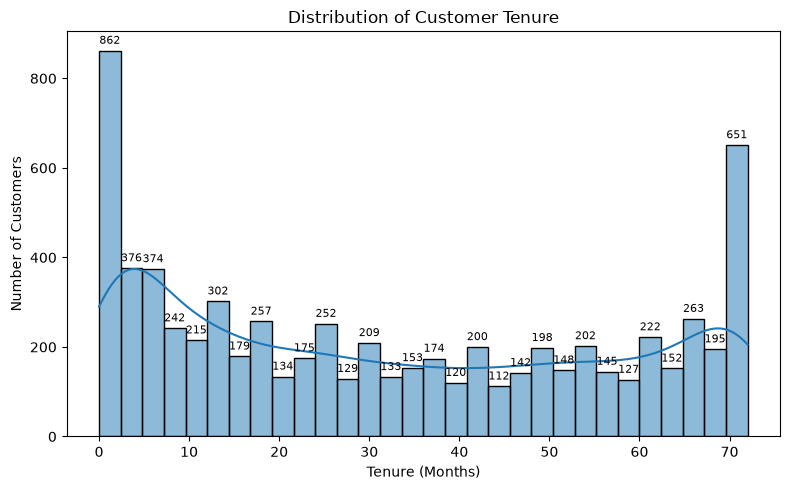

In [33]:
plt.figure(figsize=(8,5))

ax =sns.histplot(
    data = df,
    x="tenure",
    bins = 30,
    kde = True,
  
)

for bar in ax.patches:
    count = bar.get_height()

    # Skip empty bins
    if count > 0:
        ax.annotate(
            f"{count:.0f}",
            (bar.get_x() + bar.get_width() / 2, count),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
          
            textcoords="offset points"
        )


plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.show()

In [34]:
# Compare tenure between churned and retained customers

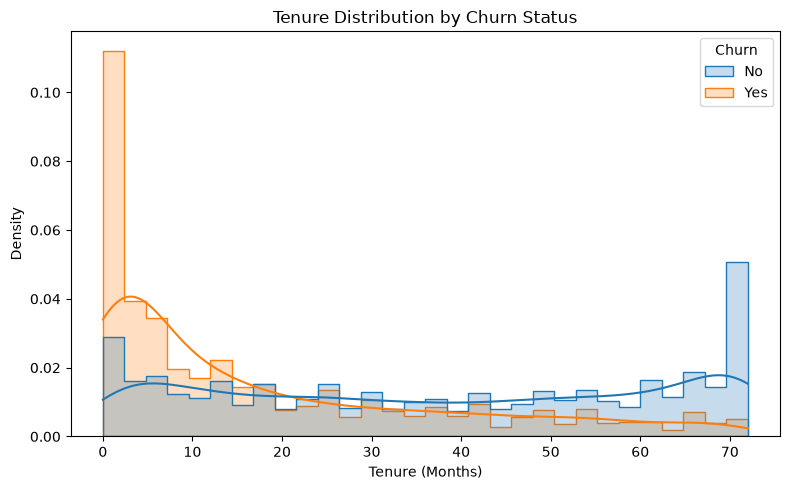

In [35]:
plt.figure(figsize=(8,5))

sns.histplot(
    data = df,
    x = "tenure",
    hue ="Churn",
    bins =30,
    kde =True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


In [36]:
# Compare average and median tenure

In [37]:
df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


#### 4.2.2 Monthly Charges

Distribution of monthly charges and comparison by churn status.

In [38]:
# Analyze MonthlyCharges

In [39]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

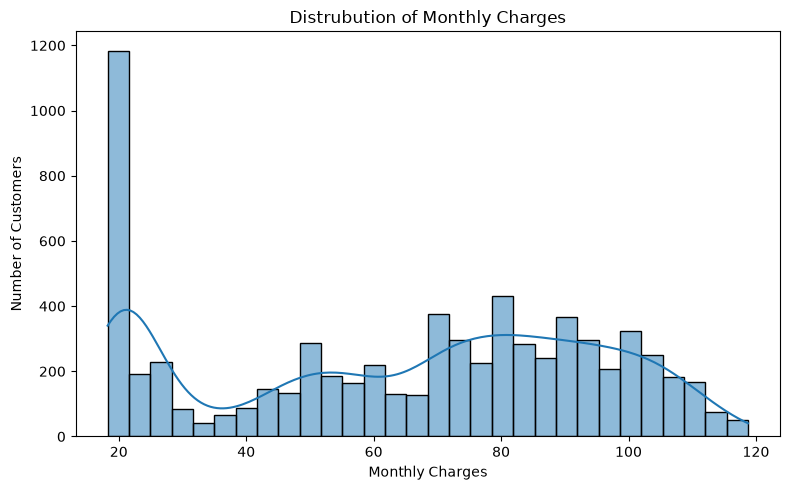

In [40]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data = df,
    x ="MonthlyCharges",
    bins =30 ,
    kde = True
)


plt.title("Distrubution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


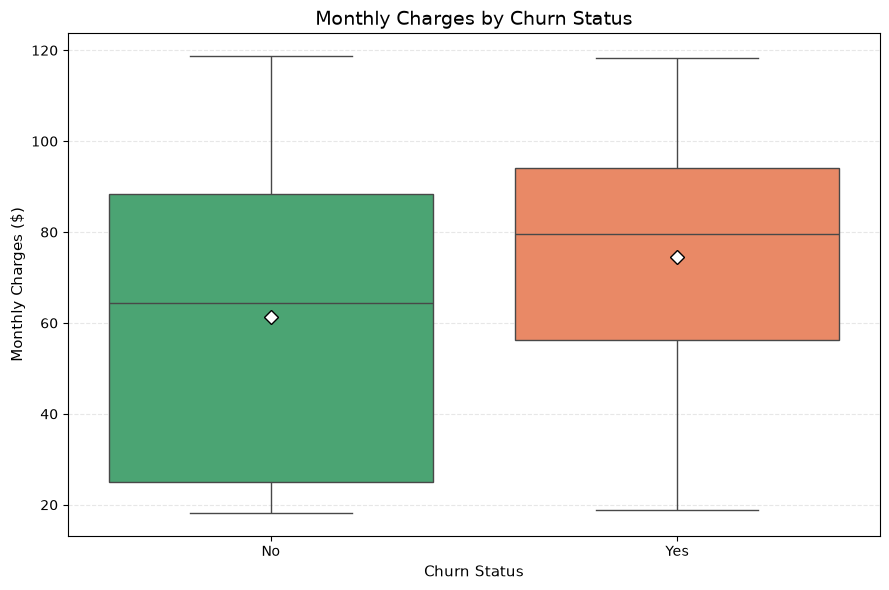

In [41]:
plt.figure(figsize=(9,6))

sns.boxplot(
    data =df,
    x ="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette={"No": "mediumseagreen", "Yes": "coral"},
    legend=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7
    }
)

plt.title("Monthly Charges by Churn Status", fontsize=14)
plt.xlabel("Churn Status", fontsize=11)
plt.ylabel("Monthly Charges ($)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


In [43]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
Churn,,,,
No,5174,61.27,64.43,31.09
Yes,1869,74.44,79.65,24.67


#### 4.2.3 Total Charges

Distribution of total charges and comparison by churn status.

In [44]:
# Analyze TotalCharges

In [45]:
df.groupby("Churn")["TotalCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,2555.344141,2329.456984,18.80,577.825,1683.60,4264.125,8672.45
Yes,1869.0,1531.796094,1890.822994,18.85,134.500,703.55,2331.300,8684.80


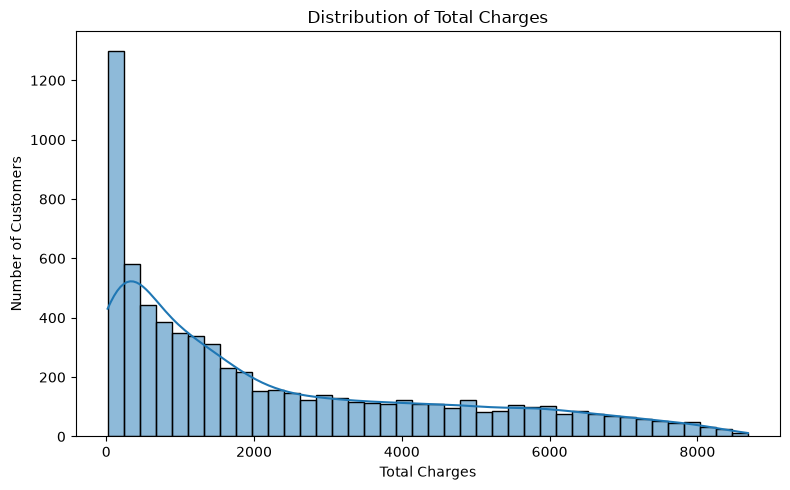

In [46]:
plt.figure(figsize=(8,5))

sns.histplot(
    data = df,
    x = "TotalCharges",
    bins = 40,
    kde = True
)

plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [47]:
# Compare total charges by churn status

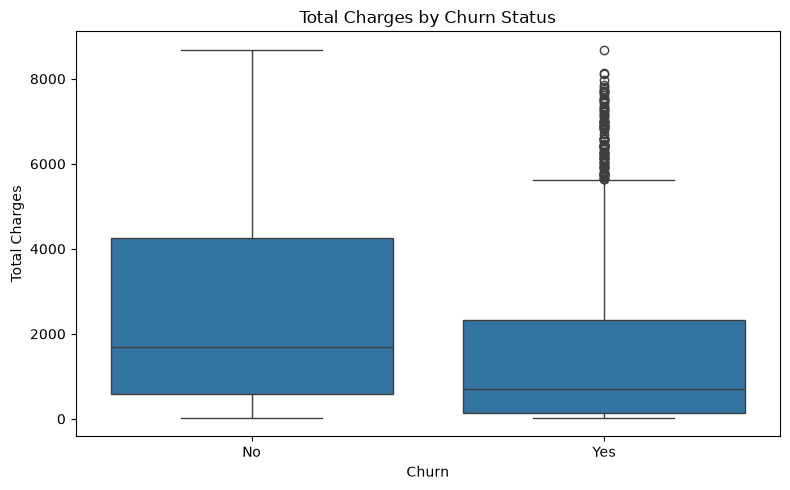

In [48]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data = df,
    x = "Churn",
    y = "TotalCharges"
    
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")
plt.tight_layout()
plt.show()

In [49]:
df.groupby("Churn")["TotalCharges"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
Churn,,,,
No,5163,2555.34,1683.60,2329.46
Yes,1869,1531.80,703.55,1890.82


#### 4.2.4 Numerical Features Summary by Churn

Average values of each numerical feature for churned and retained customers, and the difference between them.

In [50]:
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

churn_comparison = df.groupby("Churn")[
    numerical_columns
].mean().round(2)

churn_comparison

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2555.34
Yes,17.98,74.44,1531.80


In [51]:
mean_difference = (
    df[df["Churn"] == "Yes"][numerical_columns].mean()
    - df[df["Churn"] == "No"][numerical_columns].mean()
)

mean_difference.round(2)

tenure             -19.59
MonthlyCharges      13.18
TotalCharges     -1023.55
dtype: float64

### 4.3 Categorical Analysis

Churn counts and churn rates across key categorical features.

#### 4.3.1 Helper Function: Churn Rate by Category

Reusable function that calculates total customers, churned customers and churn rate for any column.

In [52]:
# Calculate churn counts and rates

In [53]:
def analyze_churn_by_category(df,column):
    summary = df.groupby(column)["Churn"].agg(
        Total_Customers="count",
        Churned_Customers=lambda x: (x == "Yes").sum()
    )
    
    summary["Churn_Rate"] = (
        summary["Churned_Customers"]
        / summary["Total_Customers"]
        * 100
    )

    return summary.sort_values(
        by="Churn_Rate",
        ascending=False
    ).round(2)

#### 4.3.2 Contract

In [54]:
analyze_churn_by_category(df, "Contract")

,Total_Customers,Churned_Customers,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


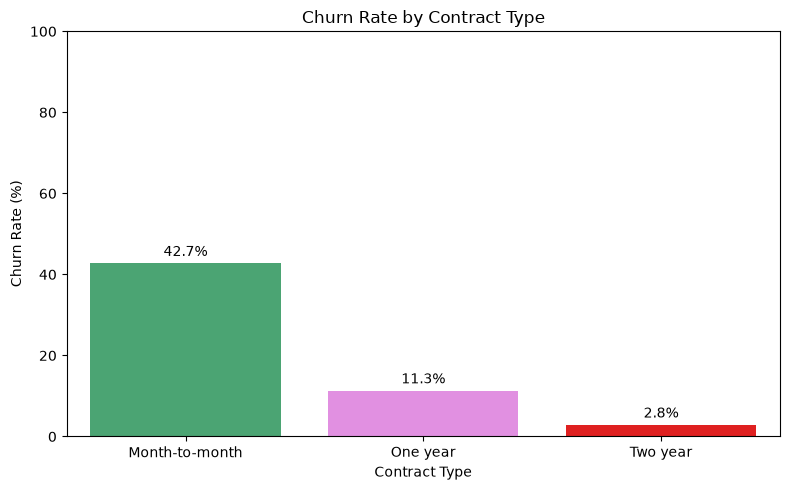

In [55]:

contract_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
#print(contract_rate)
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=contract_rate.index,
    y=contract_rate.values,
    hue=contract_rate.index,
    palette={
        "Month-to-month": "mediumseagreen",
        "One year": "violet",
        "Two year": "red"
    },
    legend=False
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points"
    )

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


#### 4.3.3 Internet Service

In [56]:
analyze_churn_by_category(df, "InternetService")

,Total_Customers,Churned_Customers,Churn_Rate
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40


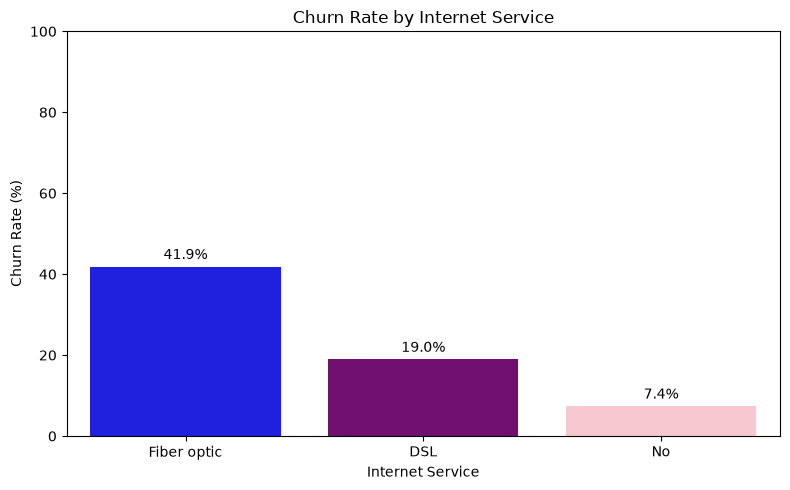

In [57]:
internet_rate = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x : (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))

ax = sns.barplot(
    x = internet_rate.index,
    y = internet_rate.values,
    hue = internet_rate.index,
    palette={
        "Fiber optic": "blue",
        "DSL": "purple",
        "No": "pink"
    },
    legend=False
    
)


for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points"
    )

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

#### 4.3.4 Payment Method

In [58]:
analyze_churn_by_category(df, "PaymentMethod")

,Total_Customers,Churned_Customers,Churn_Rate
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


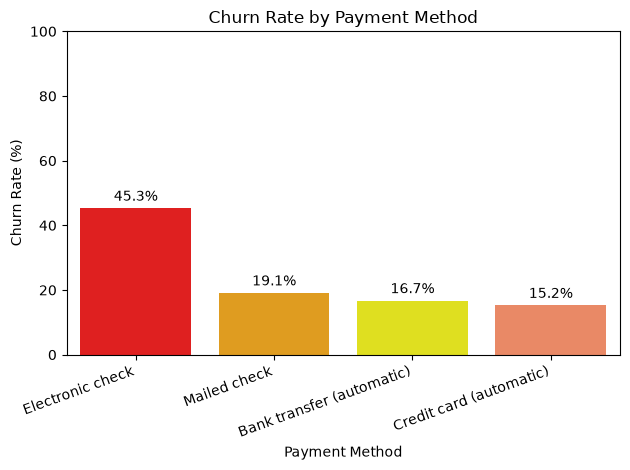

In [59]:
payment_rate = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x : (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

ax = sns.barplot(
    x =  payment_rate.index,
    y = payment_rate.values,
    hue = payment_rate.index,
    palette={
        "Electronic check": "red",
        "Mailed check": "orange",
        "Bank transfer (automatic)": "yellow",
        "Credit card (automatic)" : "coral"
    },
    legend=False
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points"
    )


plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()
    

#### 4.3.5 Tech Support

In [60]:
analyze_churn_by_category(df, "TechSupport")

,Total_Customers,Churned_Customers,Churn_Rate
TechSupport,,,
No,3473,1446,41.64
Yes,2044,310,15.17
No internet service,1526,113,7.40


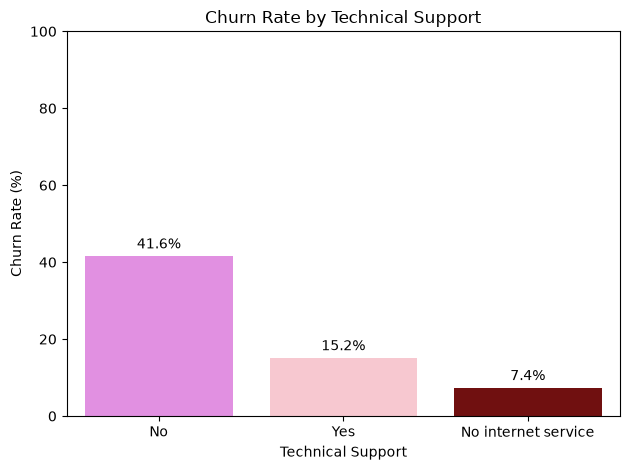

In [61]:
support_rate = (
    df.groupby("TechSupport")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

ax = sns.barplot(
    x =  support_rate.index,
    y = support_rate.values,
    hue = support_rate.index,
    palette={
        "No": "violet",
        "Yes": "pink",
        "No internet service": "maroon",
    },
    legend=False
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points"
    )


plt.title("Churn Rate by Technical Support")
plt.xlabel("Technical Support")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


#### 4.3.6 Comparison of All Four Categorical Features

In [62]:
categorical_columns = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport"
]

results = []

for column in categorical_columns:
    summary = analyze_churn_by_category(df, column)

    summary = summary.reset_index()
    summary.insert(0, "Feature", column)

    results.append(summary)

categorical_summary = pd.concat(
    results,
    ignore_index=True
)

categorical_summary

,Feature,Contract,Total_Customers,Churned_Customers,Churn_Rate,InternetService,PaymentMethod,TechSupport
0,Contract,Month-to-month,3875,1655,42.71,NaN,NaN,NaN
1,Contract,One year,1473,166,11.27,NaN,NaN,NaN
2,Contract,Two year,1695,48,2.83,NaN,NaN,NaN
3,InternetService,NaN,3096,1297,41.89,Fiber optic,NaN,NaN
4,InternetService,NaN,2421,459,18.96,DSL,NaN,NaN
5,InternetService,NaN,1526,113,7.40,No,NaN,NaN
6,PaymentMethod,NaN,2365,1071,45.29,NaN,Electronic check,NaN
7,PaymentMethod,NaN,1612,308,19.11,NaN,Mailed check,NaN
8,PaymentMethod,NaN,1544,258,16.71,NaN,Bank transfer (automatic),NaN
9,PaymentMethod,NaN,1522,232,15.24,NaN,Credit card (automatic),NaN


In [63]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


### 4.4 Relationship Analysis

How `tenure`, `MonthlyCharges` and `Contract` relate to churn.

#### 4.4.1 Selected Columns Preview

In [64]:
df[["tenure", "MonthlyCharges", "Contract", "Churn"]].head()

,tenure,MonthlyCharges,Contract,Churn
0,1,29.85,Month-to-month,No
1,34,56.95,One year,No
2,2,53.85,Month-to-month,Yes
3,45,42.30,One year,No
4,2,70.70,Month-to-month,Yes


#### 4.4.2 Tenure vs Churn

Do customers who churn have shorter relationships with the company than customers who stay?

In [65]:
# Compare tenure statistics - Do customers who churn have shorter relationships with the company than customers who stay?

In [66]:
tenure_summary = df.groupby("Churn")["tenure"].agg(["count","mean","median","min","max"])

tenure_summary.round(2)

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


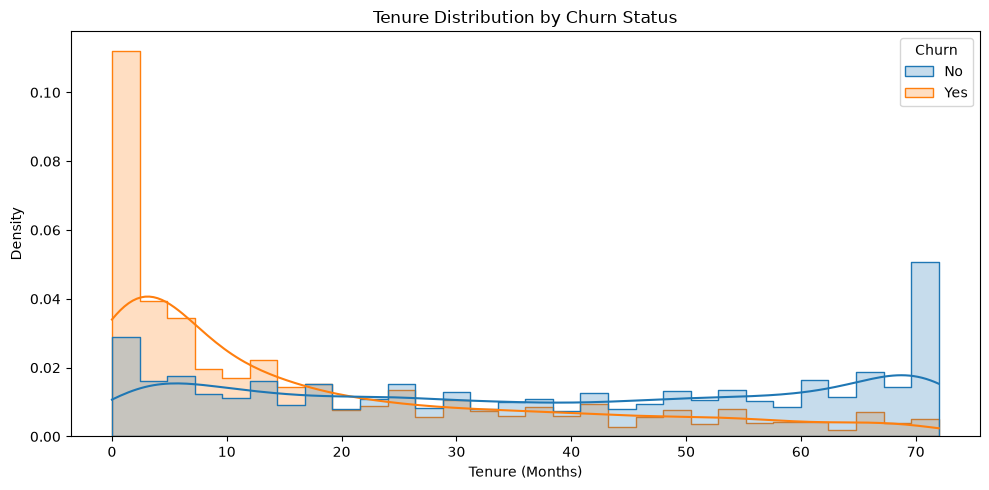

In [67]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

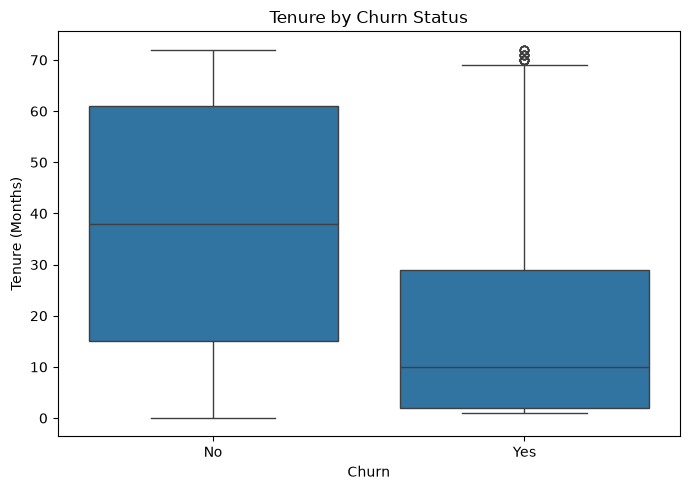

In [68]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

#### 4.4.3 Monthly Charges vs Churn

In [69]:
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

charges_summary.round(2)

,count,mean,median,std,min,max
Churn,,,,,,
No,5174,61.27,64.43,31.09,18.25,118.75
Yes,1869,74.44,79.65,24.67,18.85,118.35


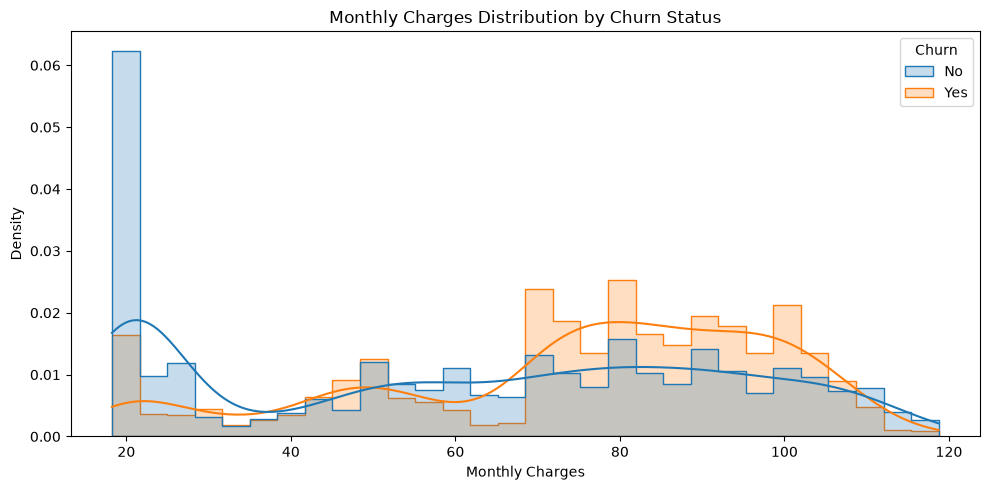

In [70]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Monthly Charges Distribution by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

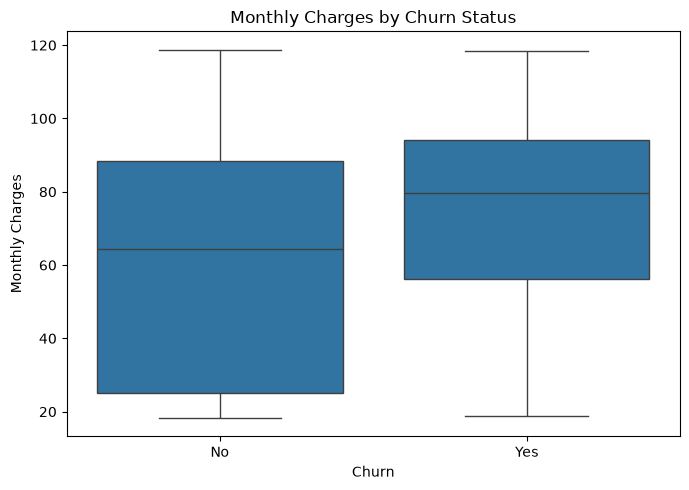

In [71]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

#### 4.4.4 Contract and Tenure Interactions

In [72]:
# Contract and tenure interactions

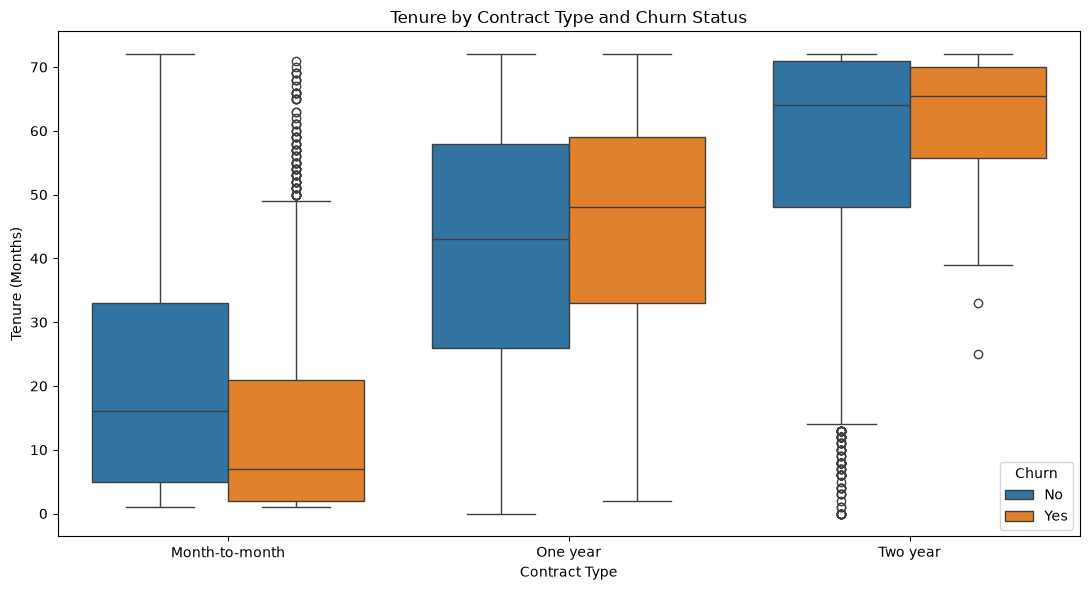

In [73]:
plt.figure(figsize=(11,6))

sns.boxplot(
    data = df,
    x = "Contract",
    y = "tenure",
    hue = "Churn"
)

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0–6 months",
        "7–12 months",
        "13–24 months",
        "25–48 months",
        "49–72 months"
    ]
)
 

plt.title("Tenure by Contract Type and Churn Status")
plt.xlabel("Contract Type")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [74]:
contract_tenure_summary = (
    df.groupby(
        ["Contract", "TenureGroup"],
        observed=True
    )["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn_Rate")
)

contract_tenure_summary.round(2)

,Contract,TenureGroup,Churn_Rate
0,Month-to-month,0–6 months,55.20
1,Month-to-month,7–12 months,42.00
2,Month-to-month,13–24 months,37.72
3,Month-to-month,25–48 months,32.92
4,Month-to-month,49–72 months,26.02
5,One year,0–6 months,10.26
6,One year,7–12 months,10.59
7,One year,13–24 months,8.12
8,One year,25–48 months,10.62
9,One year,49–72 months,12.93


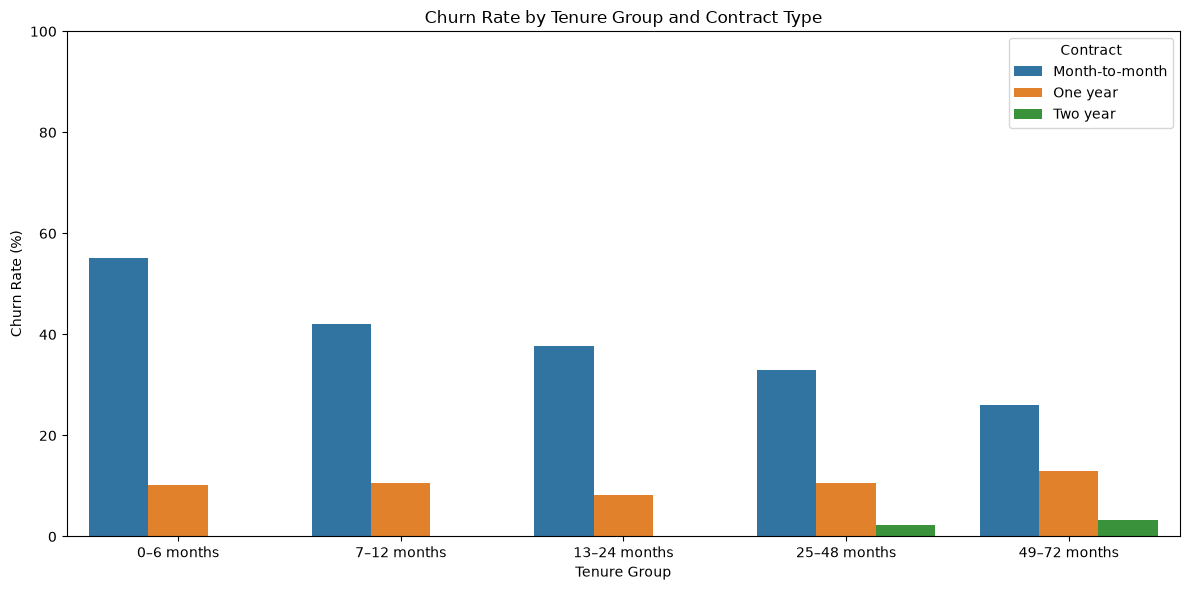

In [75]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=contract_tenure_summary,
    x="TenureGroup",
    y="Churn_Rate",
    hue="Contract"
)

plt.title("Churn Rate by Tenure Group and Contract Type")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [76]:
pd.crosstab(
    [df["Contract"], df["TenureGroup"]],
    df["Churn"]
)

Churn                          No  Yes
Contract       TenureGroup            
Month-to-month 0–6 months     633  780
               7–12 months    337  244
               13–24 months   459  278
               25–48 months   538  264
               49–72 months   253   89
One year       0–6 months      35    4
               7–12 months     76    9
               13–24 months   181   16
               25–48 months   463   55
               49–72 months   552   82
Two year       0–6 months      29    0
               7–12 months     39    0
               13–24 months    90    0
               25–48 months   268    6
               49–72 months  1221   42

#### 4.4.5 Summary Tables

Final summaries of tenure, monthly charges, and contract/tenure-group churn.

In [77]:
tenure_summary = (
    df.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

tenure_summary

,count,mean,median,std
Churn,,,,
No,5174,37.57,38.0,24.11
Yes,1869,17.98,10.0,19.53


In [78]:
charges_summary = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

charges_summary

,count,mean,median,std
Churn,,,,
No,5174,61.27,64.43,31.09
Yes,1869,74.44,79.65,24.67


In [79]:
contract_tenure_analysis = (
    df.groupby(
        ["Contract", "TenureGroup"],
        observed=True
    )["Churn"]
    .agg(
        Total_Customers="count",
        Churned_Customers=lambda x: (x == "Yes").sum()
    )
)

contract_tenure_analysis["Churn_Rate"] = (
    contract_tenure_analysis["Churned_Customers"]
    / contract_tenure_analysis["Total_Customers"]
    * 100
)

contract_tenure_analysis.round(2)

Total_Customers  Churned_Customers  Churn_Rate
Contract       TenureGroup                                                 
Month-to-month 0–6 months               1413                780       55.20
               7–12 months               581                244       42.00
               13–24 months              737                278       37.72
               25–48 months              802                264       32.92
               49–72 months              342                 89       26.02
One year       0–6 months                 39                  4       10.26
               7–12 months                85                  9       10.59
               13–24 months              197                 16        8.12
               25–48 months              518                 55       10.62
               49–72 months              634                 82       12.93
Two year       0–6 months                 29                  0        0.00
               7–12 months                39                  0        0.00
               13–24 months               90                  0        0.00
               25–48 months              274                  6        2.19
               49–72 months             1263                 42        3.33